# 02 · Profundidad de los pseudobulk y control técnico

En el notebook 01 vimos que, dentro de cada tipo celular, la primera componente principal sigue sobre todo al
**número de células** de cada pseudobulk, y que ese número baja de Low a High por cómo se construyó el subset.

Aquí hacemos tres cosas:

1. **Modelo trampa:** ¿cuánto acierta un clasificador que solo ve el número de células y de recuentos? Ese es
   el listón que cualquier modelo de expresión tiene que superar.
2. **Igualar la profundidad** por submuestreo binomial dentro de cada tipo celular.
3. **Repetir la PCA** para comprobar si el efecto técnico desaparece.

**Ejecución:** `jupyter nbconvert --to notebook --execute --inplace notebooks\02_profundidad_y_control.ipynb`

In [1]:
import json
import sys
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tfm import evaluation as E
from tfm import pseudobulk as P
from tfm.config import load_config

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

cfg = load_config(ROOT)
COL, PB, EV = cfg["columns"], cfg["pseudobulk"], cfg["evaluation"]
CT, LAB = COL["cell_type"], COL["label"]
ORDEN, SEED = cfg["labels"]["classification"], cfg["seed"]
TABLAS, FIGS = cfg["paths"]["tables"], cfg["paths"]["figures"]
PALETA = dict(zip(ORDEN, ["#4daf4a", "#ff7f00", "#e41a1c"]))

def guardar(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", encoding="utf-8"); return df

def guardar_fig(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", dpi=150, bbox_inches="tight")

pb = ad.read_h5ad(ROOT / PB["file"])
print(pb)

AnnData object with n_obs × n_vars = 472 × 36412
    obs: 'donor_id', 'cell_type_abbr', 'n_celulas', 'total_counts', 'n_genes_detectados', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'Neurotypical reference', 'Age at death', 'Years of education', 'Cognitive status', 'ADNC', 'Braak stage', 'Thal phase', 'CERAD score', 'APOE4 status', 'Lewy body disease pathology', 'LATE-NC stage', 'Microinfarct pathology', 'PMI', 'suspension_type', 'development_stage_ontology_term_id', 'Continuous Pseudo-progression Score', 'tissue_type', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage'
    var: 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'simbolo', 'en_X_hvg'
    uns: 'pseudobulk'


## 1. Modelo trampa

Construimos una tabla con **una fila por donante** (75, sin Reference) y, como únicas características, el
logaritmo del número de células y de recuentos de cada uno de sus 6 tipos celulares. Ninguna contiene
expresión génica.

Validación cruzada **por donante**: 5 pliegues estratificados por clase, repetidos 20 veces con particiones
distintas. Comparamos con predecir siempre la clase mayoritaria (High), que es el azar:
balanced accuracy = 1/3 y kappa = 0.

In [2]:
Xt, y = E.technical_features(pb, cfg)
splits = E.donor_splits(y.values, n_splits=EV["n_splits"], n_repeats=EV["n_repeats"], seed=SEED)
logistica = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced"))

col_cel = [c for c in Xt.columns if c.startswith("n_celulas")]
col_rec = [c for c in Xt.columns if c.startswith("total_counts")]
res_trampa = {
    "azar (siempre High)": E.cross_validate(Xt, y, lambda: DummyClassifier(strategy="most_frequent"), splits, ORDEN)[0],
    "trampa: n_celulas": E.cross_validate(Xt[col_cel], y, logistica, splits, ORDEN)[0],
    "trampa: total_counts": E.cross_validate(Xt[col_rec], y, logistica, splits, ORDEN)[0],
    "trampa: ambas": E.cross_validate(Xt, y, logistica, splits, ORDEN)[0],
}
tabla_trampa = guardar(E.summarize(res_trampa), "control_tecnico_cv")
display(tabla_trampa.round(3))

,balanced_accuracy_media,balanced_accuracy_sd,f1_macro_media,f1_macro_sd,kappa_cuadratico_media,kappa_cuadratico_sd
modelo,,,,,,
azar (siempre High),0.333,0.000,0.239,0.000,0.000,0.000
trampa: n_celulas,0.660,0.027,0.645,0.026,0.710,0.020
trampa: total_counts,0.652,0.028,0.634,0.026,0.691,0.024
trampa: ambas,0.644,0.025,0.630,0.026,0.693,0.019


Si la trampa acierta mucho más que el azar, cualquier modelo que vea los pseudobulk **sin igualar** puede estar
aprendiendo el número de células en vez de la enfermedad. Por eso igualamos la profundidad antes de modelar y, al
evaluar los modelos de expresión, los compararemos siempre con esta trampa.

## 2. Igualar la profundidad: elegir el objetivo

**Submuestreo binomial.** Para un pseudobulk con `T` recuentos totales, cada recuento `x` de cada gen se sustituye
por un valor aleatorio `Binomial(x, D/T)`. Es como si se hubieran secuenciado solo `D` lecturas: el total queda
en ~`D` y las proporciones entre genes se conservan. Es el equivalente a **diezmar** todas las señales a la misma
tasa para que ninguna clase tenga más SNR que otra.

El objetivo `D` se fija **por tipo celular** (cada tipo tiene un tamaño de núcleo y un nivel de ARN distinto) como
un cuantil de `total_counts`. Los pseudobulk por debajo de `D`, o con menos de `min_cells` células, se descartan.
Cuanto más alto el cuantil, menos ruido, pero más pseudobulk de High se pierden.

In [3]:
perdidas = guardar(P.thinning_losses(pb, cfg, PB["depth_quantiles_explorar"], PB["min_cells"]), "igualado_perdidas_por_cuantil")
display(perdidas)
print(f"Cuantil elegido en el config: {PB['depth_quantile']}  |  min_cells: {PB['min_cells']}")

,profundidad_mediana_objetivo,pierde_Low,queda_Low,pierde_Intermediate,queda_Intermediate,pierde_High,queda_High
cuantil,,,,,,,
0.00,61186.5,1,71,2,124,40,208
0.05,125135.1,1,71,4,122,62,186
0.10,164898.8,1,71,9,117,75,173
0.25,259951.0,2,70,21,105,122,126


Cuantil elegido en el config: 0.05  |  min_cells: 10


In [4]:
pb_ig, informe = P.downsample_to_depth(pb, cfg, quantile=PB["depth_quantile"], min_cells=PB["min_cells"], seed=SEED)
guardar(informe, "igualado_informe_por_tipo")
display(informe)
pb_ig.write_h5ad(ROOT / PB["file_igualado"], compression="gzip")
print(pb_ig)

rel = pb_ig.obs["total_counts"] / pb_ig.obs[CT].map(pb_ig.uns["igualado"]["objetivo_por_tipo"]).astype(float)
print(f"\nTotal tras igualar / objetivo: mín {rel.min():.3f}, máx {rel.max():.3f}")
donantes_quedan = pb_ig.obs.groupby(LAB, observed=True)[COL["donor"]].nunique().reindex(ORDEN)
print("Donantes con al menos un pseudobulk:", donantes_quedan.to_dict())

,objetivo,queda_Low,queda_Intermediate,queda_High,pierde_Low,pierde_Intermediate,pierde_High
cell_type_abbr,,,,,,,
AST,107727.60,12,20,32,0,1,9
L2IT-GLU,317113.30,12,20,31,0,1,11
MGC,81865.80,12,20,31,0,1,11
OLG,70023.70,11,20,29,1,1,11
SST-GABA,142542.60,12,21,30,0,0,11
VIP-GABA,148519.05,12,21,33,0,0,9


AnnData object with n_obs × n_vars = 379 × 36412
    obs: 'donor_id', 'cell_type_abbr', 'n_celulas', 'total_counts', 'n_genes_detectados', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'Neurotypical reference', 'Age at death', 'Years of education', 'Cognitive status', 'ADNC', 'Braak stage', 'Thal phase', 'CERAD score', 'APOE4 status', 'Lewy body disease pathology', 'LATE-NC stage', 'Microinfarct pathology', 'PMI', 'suspension_type', 'development_stage_ontology_term_id', 'Continuous Pseudo-progression Score', 'tissue_type', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'total_counts_original'
    var: 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'simbolo', 'en_X_hvg'
    uns: 'pseudobulk', 'igualado'

Total tras igualar / objetivo: mín 0.991, máx 1.009
Donantes con al menos un pseudobulk: {'Low': 

## 3. ¿Ha desaparecido el efecto técnico?

Repetimos la PCA dentro de cada tipo celular, antes y después de igualar, y medimos el R² de cada componente con
el ADNC, con `log n_celulas` y con `log total_counts`.

- **`log total_counts`** debería caer a casi 0 después de igualar: todos tienen ya la misma profundidad.
- **`log n_celulas`** puede no desaparecer del todo. Igualar recuentos no iguala el número de células: un
  pseudobulk de 15 células sigue siendo una muestra más pequeña de la población del donante que uno de 70.

log n_celulas         log total_counts          ADNC        
                 antes despues            antes despues antes despues
tipo                                                                 
AST               0.18    0.01             0.23    0.03  0.19    0.13
L2IT-GLU          0.70    0.05             0.80    0.01  0.15    0.06
MGC               0.68    0.01             0.65    0.00  0.23    0.07
OLG               0.81    0.16             0.77    0.00  0.13    0.04
SST-GABA          0.76    0.29             0.84    0.05  0.19    0.07
VIP-GABA          0.67    0.05             0.75    0.07  0.20    0.05

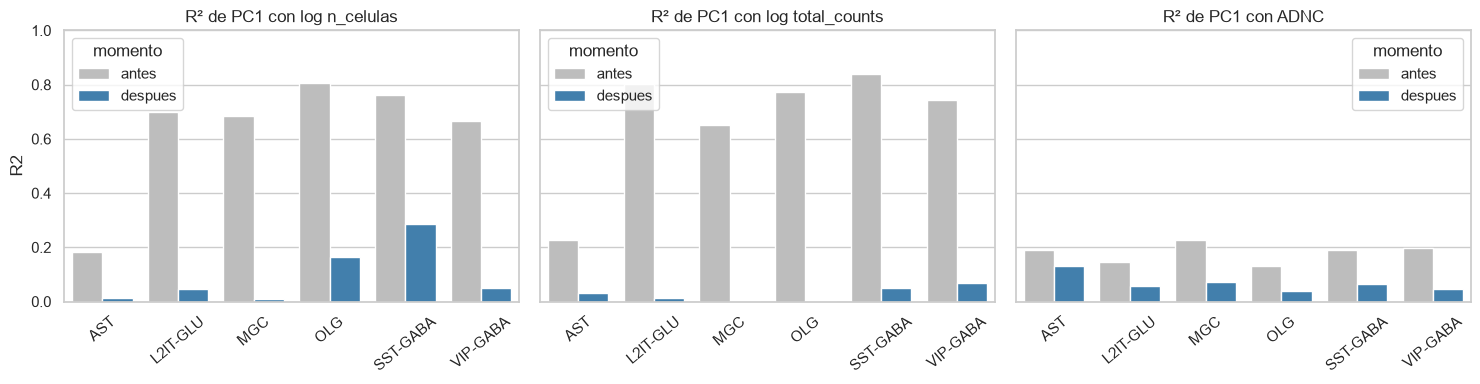

In [5]:
r2_antes, _ = P.pca_r2_by_type(pb, cfg, PB["min_cpm"], PB["min_frac"], PB["n_hvg_pca"], seed=SEED)
r2_despues, pcas = P.pca_r2_by_type(pb_ig, cfg, PB["min_cpm"], PB["min_frac"], PB["n_hvg_pca"], seed=SEED)
r2 = pd.concat({"antes": r2_antes, "despues": r2_despues}, names=["momento"]).reset_index(level=0)
guardar(r2, "igualado_pca_r2_antes_despues")

pc1 = r2[r2["PC"] == "PC1"].pivot_table(index="tipo", columns=["variable", "momento"], values="R2")
pc1 = pc1.reindex(columns=pd.MultiIndex.from_product([["log n_celulas", "log total_counts", "ADNC"], ["antes", "despues"]]))
display(pc1.round(2))

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, var in zip(axs, ["log n_celulas", "log total_counts", "ADNC"]):
    d = r2[(r2["PC"] == "PC1") & (r2["variable"] == var)]
    sns.barplot(data=d, x="tipo", y="R2", hue="momento", ax=ax, palette=["#bdbdbd", "#3182bd"])
    ax.set_title(f"R² de PC1 con {var}"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40)
    ax.set_ylim(0, 1)
fig.tight_layout(); guardar_fig(fig, "igualado_r2_pc1"); plt.show()

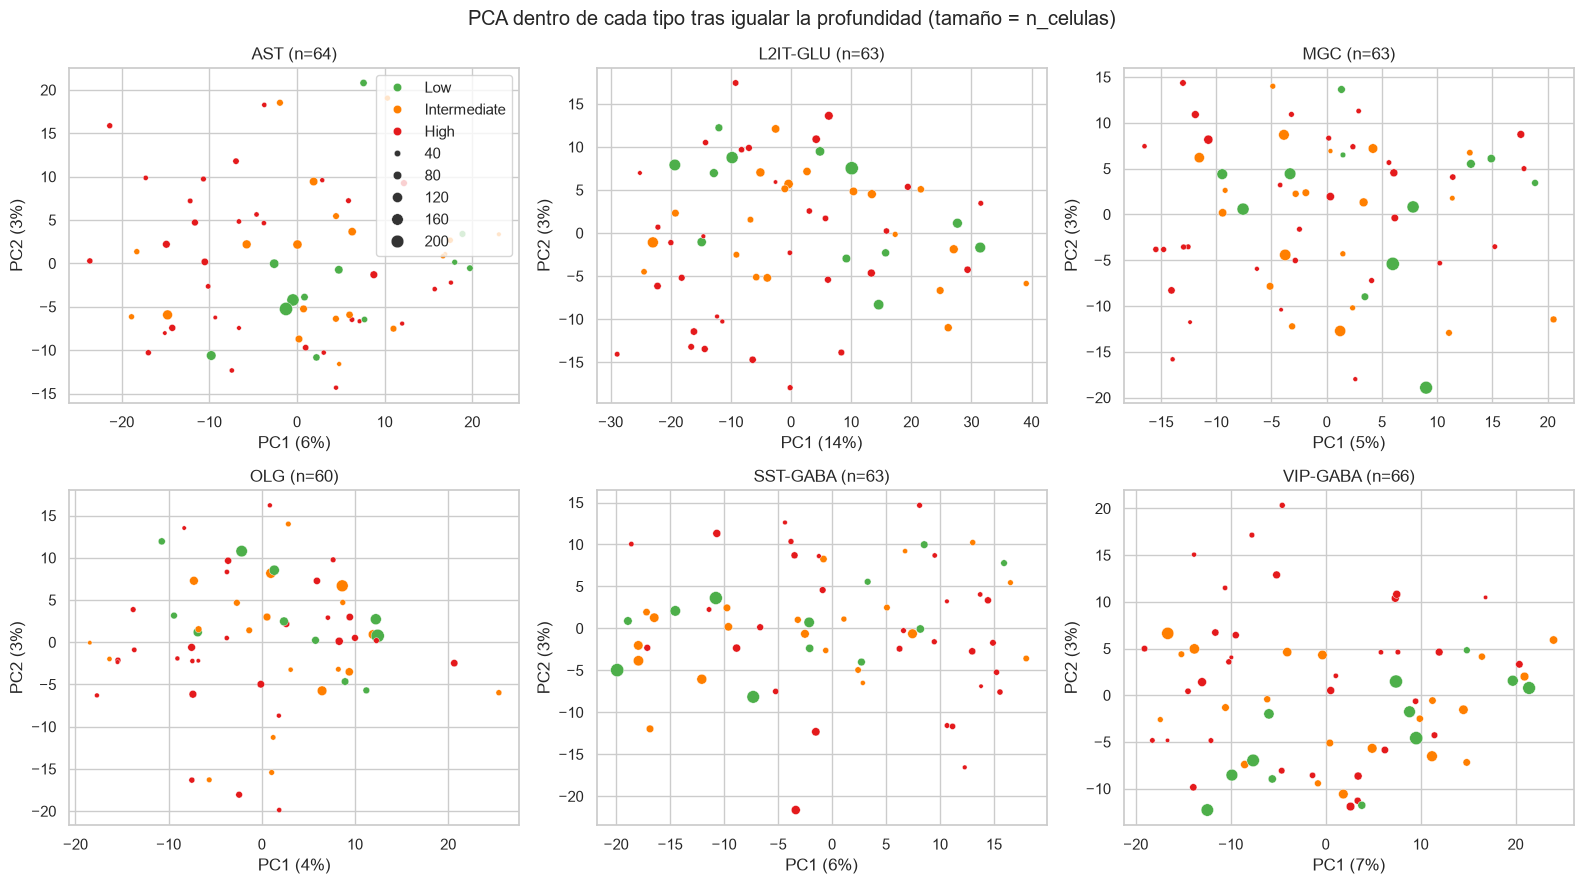

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for ax, (t, (p, v, sub)) in zip(axs.ravel(), pcas.items()):
    sns.scatterplot(x=p[:, 0], y=p[:, 1], hue=sub[LAB].astype(str).values, hue_order=ORDEN, palette=PALETA,
                    size=sub["n_celulas"].values, sizes=(10, 90), ax=ax, legend=(t == list(pcas)[0]))
    ax.set_title(f"{t} (n={len(sub)})"); ax.set_xlabel(f"PC1 ({v[0]:.0%})"); ax.set_ylabel(f"PC2 ({v[1]:.0%})")
fig.suptitle("PCA dentro de cada tipo tras igualar la profundidad (tamaño = n_celulas)")
fig.tight_layout(); guardar_fig(fig, "igualado_pca_por_tipo"); plt.show()

In [7]:
resumen = {
    "trampa_balanced_accuracy": tabla_trampa["balanced_accuracy_media"].round(3).to_dict(),
    "trampa_kappa": tabla_trampa["kappa_cuadratico_media"].round(3).to_dict(),
    "cuantil": PB["depth_quantile"], "min_cells": PB["min_cells"],
    "objetivo_por_tipo": pb_ig.uns["igualado"]["objetivo_por_tipo"],
    "pseudobulk_igualados": int(pb_ig.n_obs),
    "quedan_por_clase": pb_ig.obs[LAB].value_counts().reindex(ORDEN).to_dict(),
    "donantes_por_clase": donantes_quedan.to_dict(),
    "R2_PC1_log_n_celulas": {m: r2[(r2.PC == "PC1") & (r2.variable == "log n_celulas") & (r2.momento == m)]
                             .set_index("tipo")["R2"].round(2).to_dict() for m in ["antes", "despues"]},
    "R2_PC1_ADNC": {m: r2[(r2.PC == "PC1") & (r2.variable == "ADNC") & (r2.momento == m)]
                    .set_index("tipo")["R2"].round(2).to_dict() for m in ["antes", "despues"]},
}
(TABLAS / "igualado_resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False, default=str))

{
  "trampa_balanced_accuracy": {
    "azar (siempre High)": 0.333,
    "trampa: n_celulas": 0.66,
    "trampa: total_counts": 0.652,
    "trampa: ambas": 0.644
  },
  "trampa_kappa": {
    "azar (siempre High)": 0.0,
    "trampa: n_celulas": 0.71,
    "trampa: total_counts": 0.691,
    "trampa: ambas": 0.693
  },
  "cuantil": 0.05,
  "min_cells": 10,
  "objetivo_por_tipo": {
    "AST": 107727.6,
    "L2IT-GLU": 317113.3,
    "MGC": 81865.8,
    "OLG": 70023.7,
    "SST-GABA": 142542.6,
    "VIP-GABA": 148519.05
  },
  "pseudobulk_igualados": 379,
  "quedan_por_clase": {
    "Low": 71,
    "Intermediate": 122,
    "High": 186
  },
  "donantes_por_clase": {
    "Low": 12,
    "Intermediate": 21,
    "High": 41
  },
  "R2_PC1_log_n_celulas": {
    "antes": {
      "AST": 0.18,
      "L2IT-GLU": 0.7,
      "MGC": 0.68,
      "OLG": 0.81,
      "SST-GABA": 0.76,
      "VIP-GABA": 0.67
    },
    "despues": {
      "AST": 0.01,
      "L2IT-GLU": 0.05,
      "MGC": 0.01,
      "OLG": 0.16,
 